In [1]:
import numpy as np
import matplotlib.pyplot as plt


plt.style.use(
    [
        "dark_background",
        "https://raw.githubusercontent.com/cfrontin/tools_cvf/main/tools_cvf/stylesheet_cvf.mplstyle",
        "https://raw.githubusercontent.com/cfrontin/tools_cvf/main/tools_cvf/stylesheet_nrel.mplstyle",
    ]
)

## Compressible oriface flow model

Compressible oriface flow should be what dictates throttle body flow when throttle state approaches closed.


In [2]:
def nondim_force_deficit(
    Ci,  # incompressible contraction coefficient (-)
):
    # nondimensional force deficit as a function of contraction coefficient
    return Ci ** (-1) - 0.5 * Ci ** (-2)

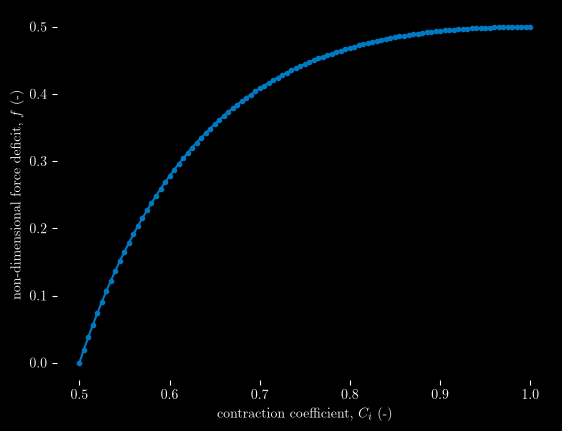

In [3]:
def plot_nondim_force_deficit():
    Ci_vec = np.linspace(0.5, 1.0, 101)
    _fig, ax = plt.subplots()
    f = nondim_force_deficit(Ci_vec)
    ax.plot(Ci_vec, f, ".-")
    ax.set_xlabel("contraction coefficient, $C_i$ (-)")
    ax.set_ylabel("non-dimensional force deficit, $f$ (-)")
    plt.show()


plot_nondim_force_deficit()

In [4]:
def r_critical(
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    return (2 / (n + 1)) ** (n / (n - 1))  # critical pressure ratio for a nozzle (-)


def K_nozzle(
    r,  # pressure ratio (-)
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    r = np.atleast_1d(r)  # flatten out
    r_w = np.maximum(r, r_critical(n=n))
    # mass flow coefficient for a nozzle as a function of pressure ratio
    return np.sqrt((2 * n / (n - 1)) * r_w ** (2 / n) * (1 - r_w ** ((n - 1) / n)))

In [5]:
np.isclose(K_nozzle(r_critical()), np.sqrt(1.4 * (2 / (1.4 + 1)) ** ((1.4 + 1) / (1.4 - 1))))

array([ True])

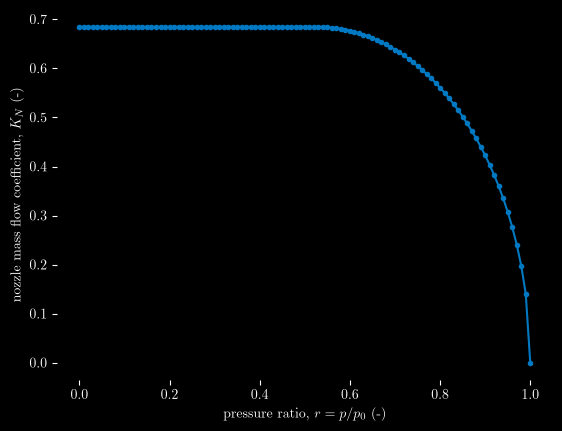

In [6]:
def plot_K_nozzle():
    r_vec = np.linspace(0.0, 1.0, 101)
    _fig, ax = plt.subplots()
    K_vec = K_nozzle(r_vec)
    ax.plot(r_vec, K_vec, ".-")
    ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
    ax.set_ylabel("nozzle mass flow coefficient, $K_N$ (-)")
    plt.show()


plot_K_nozzle()

In [7]:
def C_subcritical(
    r,  # pressure ratio (-)
    f=None,  # nondimensional force deficit (-), can be specified using Ci instead
    Ci=None,  # contraction coefficient (-), can be used to compute f if not specified
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    if Ci is not None:
        f = nondim_force_deficit(Ci)
    elif f is None:
        raise ValueError("Either Ci or f must be specified")
    K_N = K_nozzle(r, n=n)
    return (
        1
        / (2 * f * r ** (1 / n))
        * (1 - np.sqrt(1 - (2 * r ** (1 / n)) ** 2 * (1 - r) * f / (K_N**2)))
    )  # 0.5*f**(-1)*r**(-1/n)*(1 - np.sqrt(1 - (2*r**(1/n))**2*(1-r)*f/K_nozzle(r, n=n)))

/var/folders/37/w751_gtn1blbrqj8vjy1vhv8czhwm5/T/ipykernel_30057/1425129712.py:10: RuntimeWarning: divide by zero encountered in divide
  return 1/(2*f*r**(1/n))*(
/var/folders/37/w751_gtn1blbrqj8vjy1vhv8czhwm5/T/ipykernel_30057/1425129712.py:11: RuntimeWarning: invalid value encountered in divide
  1 - np.sqrt(1 - (2*r**(1/n))**2*(1-r)*f/(K_N**2))
/var/folders/37/w751_gtn1blbrqj8vjy1vhv8czhwm5/T/ipykernel_30057/1425129712.py:10: RuntimeWarning: invalid value encountered in multiply
  return 1/(2*f*r**(1/n))*(


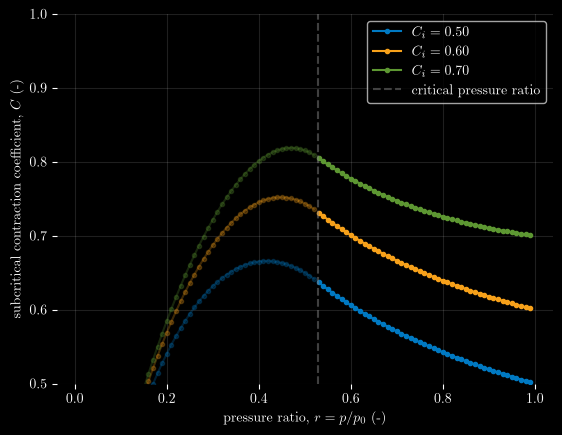

In [8]:
def plot_C_subcritical():
    r_vec = np.linspace(0.0, 1.0, 101)
    _fig, ax = plt.subplots()
    for Ci in [0.5 + 1e-6, 0.6, 0.7]:  # , 0.8, 0.9, 1.0]:
        C_vec = C_subcritical(r_vec, Ci=Ci)
        ax.plot(
            r_vec[r_vec > r_critical()],
            C_vec[r_vec > r_critical()],
            ".-",
            alpha=1.0,
            label=f"$C_i={Ci:.2f}$",
        )
        ax.plot(
            r_vec[r_vec <= r_critical()],
            C_vec[r_vec <= r_critical()],
            ".-",
            c=ax.lines[-1].get_color(),
            alpha=0.25,
            label=f"_$C_i={Ci:.2f}$_",
        )
    ax.axvline(
        r_critical(),
        color=(0.5, 0.5, 0.5),
        alpha=0.5,
        linestyle="--",
        label="critical pressure ratio",
    )
    ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
    ax.set_ylabel("subcritical contraction coefficient, $C$ (-)")
    ax.legend()
    ax.set_ylim(0.5, 1.0)
    ax.grid(alpha=0.125)
    plt.show()


plot_C_subcritical()

In [9]:
def C_supercritical(
    r,  # pressure ratio (-)
    f=None,  # nondimensional force deficit (-), can be specified using Ci instead
    Ci=None,  # contraction coefficient (-), can be used to compute f if not specified
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    if Ci is not None:
        f = nondim_force_deficit(Ci)
    elif f is None:
        raise ValueError("Either Ci or f must be specified")
    r_c = r_critical(n=n)
    K_N = K_nozzle(r_c, n=n)
    # term_a = f
    # term_b = -1/(r_c**(1/n))*(1 + (r_c - r)*r_c**(1/n)/(K_N**2))
    # term_c = (1-r)/(K_N**2)
    # # return (-term_b + np.sqrt(term_b**2 - 4*term_a*term_c))/(2*term_a)
    # return (-term_b - np.sqrt(term_b**2 - 4*term_a*term_c))/(2*term_a)
    term_A = 1 + (r_c - r) * (r_c ** (1 / n)) / (K_N**2)
    term_B = term_A**2 - (2 * r_c ** (1 / n)) ** 2 * (1 - r) * f / (K_N**2)
    return 1 / (2 * f * r_c ** (1 / n)) * (term_A - np.sqrt(term_B))

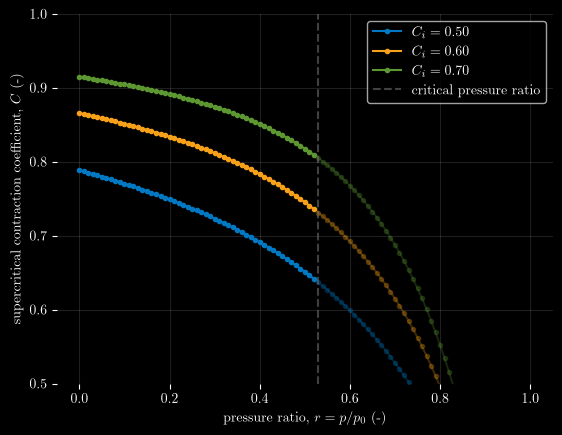

In [10]:
def plot_C_supercritical():
    r_vec = np.linspace(0.0, 1.0, 101)
    _fig, ax = plt.subplots()
    for Ci in [0.5 + 1e-6, 0.6, 0.7]:  # , 0.8, 0.9, 1.0]:
        C_vec = C_supercritical(r_vec, Ci=Ci)
        ax.plot(
            r_vec[r_vec <= r_critical()],
            C_vec[r_vec <= r_critical()],
            ".-",
            alpha=1.0,
            label=f"$C_i={Ci:.2f}$",
        )
        ax.plot(
            r_vec[r_vec > r_critical()],
            C_vec[r_vec > r_critical()],
            ".-",
            c=ax.get_lines()[-1].get_color(),
            alpha=0.25,
            label=f"_$C_i={Ci:.2f}$_",
        )
    ax.axvline(
        r_critical(),
        color=(0.5, 0.5, 0.5),
        alpha=0.5,
        linestyle="--",
        label="critical pressure ratio",
    )
    ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
    ax.set_ylabel("supercritical contraction coefficient, $C$ (-)")
    ax.legend()
    ax.set_ylim(0.5, 1.0)
    ax.grid(alpha=0.125)
    plt.show()


plot_C_supercritical()

In [11]:
def C_full(
    r,  # pressure ratio (-)
    f=None,  # nondimensional force deficit (-), can be specified using Ci instead
    Ci=None,  # contraction coefficient (-), can be used to compute f if not specified
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    r = np.atleast_1d(r)  # flatten out
    r_c = r_critical(n=n)
    C_val = np.zeros_like(r)
    C_val[r > r_c] = C_subcritical(r[r > r_c], f=f, Ci=Ci, n=n)
    C_val[r <= r_c] = C_supercritical(r[r <= r_c], f=f, Ci=Ci, n=n)
    return C_val

/var/folders/37/w751_gtn1blbrqj8vjy1vhv8czhwm5/T/ipykernel_30057/1425129712.py:11: RuntimeWarning: invalid value encountered in divide
  1 - np.sqrt(1 - (2*r**(1/n))**2*(1-r)*f/(K_N**2))


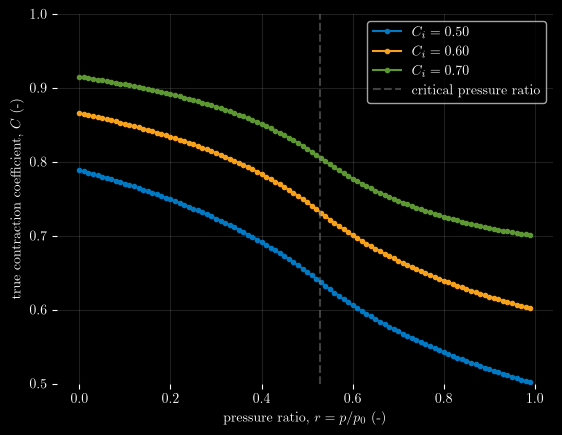

In [12]:
def plot_C_full():
    r_vec = np.linspace(0.0, 1.0, 101)
    _fig, ax = plt.subplots()
    for Ci in [0.5 + 1e-6, 0.6, 0.7]:  # , 0.8, 0.9, 1.0]:
        C_vec = C_full(r_vec, Ci=Ci)
        ax.plot(r_vec, C_vec, ".-", label=f"$C_i={Ci:.2f}$")
    ax.axvline(
        r_critical(),
        color=(0.5, 0.5, 0.5),
        alpha=0.5,
        linestyle="--",
        label="critical pressure ratio",
    )
    ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
    ax.set_ylabel("true contraction coefficient, $C$ (-)")
    ax.legend()
    ax.set_ylim(0.5, 1.0)
    ax.grid(alpha=0.125)
    plt.show()


plot_C_full()

In [13]:
# the above should match the expected behavior of the supercritical contraction
# coefficient plot from the Jobson paper

In [14]:
def K_full(
    r,  # pressure ratio (-)
    f=None,  # nondimensional force deficit (-), can be specified using Ci instead
    Ci=None,  # contraction coefficient (-), can be used to compute f if not specified
    n=1.4,  # gas law constant => gamma for near-perfect gases => 1.4 for diatomic gases like air
):
    K_N = K_nozzle(r, n=n)
    C_val = C_full(r, f=f, Ci=Ci, n=n)
    return C_val * K_N

/var/folders/37/w751_gtn1blbrqj8vjy1vhv8czhwm5/T/ipykernel_30057/1425129712.py:11: RuntimeWarning: invalid value encountered in divide
  1 - np.sqrt(1 - (2*r**(1/n))**2*(1-r)*f/(K_N**2))


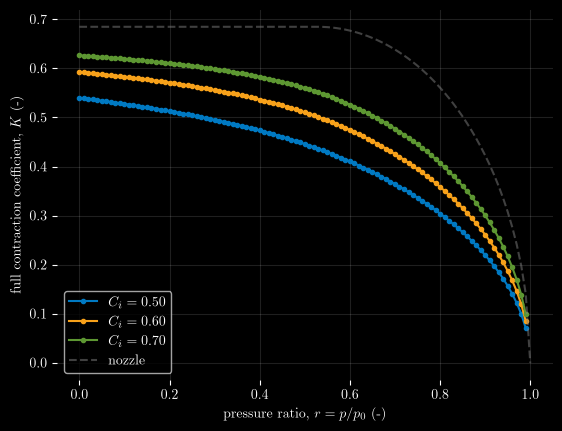

In [15]:
def plot_K_full():
    r_vec = np.linspace(0.0, 1.0, 101)
    _fig, ax = plt.subplots()
    for Ci in [0.5 + 1e-6, 0.6, 0.7]:  # , 0.8, 0.9, 1.0]:
        K_vec = K_full(r_vec, Ci=Ci)
        ax.plot(
            r_vec,
            K_vec,
            ".-",
            alpha=1.0,
            label=f"$C_i={Ci:.2f}$",
        )
    ax.plot(r_vec, K_nozzle(r_vec), "--", color=(0.5, 0.5, 0.5), alpha=0.5, label="nozzle")
    ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
    ax.set_ylabel("full contraction coefficient, $K$ (-)")
    ax.legend()
    ax.grid(alpha=0.125)
    plt.show()


plot_K_full()

## Driving an engine model w/ an oriface throttle model

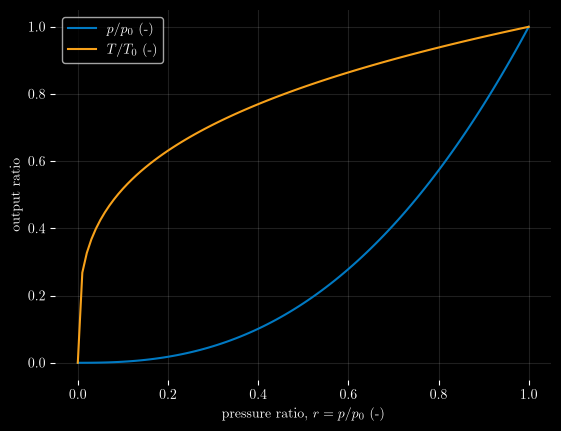

In [57]:
# use the reversible adiabatic density ratio relation
def density_ratio_rev_adiabatic(pressure_ratio, n=1.4):
    return pressure_ratio ** (-1 / (1 - n))


def temperature_ratio_rev_adiabatic(pressure_ratio, n=1.4):
    return pressure_ratio ** ((n - 1) / n)


fig, ax = plt.subplots()
ax.plot(
    np.linspace(0.0, 1.0, 101),
    density_ratio_rev_adiabatic(np.linspace(0.0, 1.0, 101)),
    label="$p/p_0$ (-)",
)
ax.plot(
    np.linspace(0.0, 1.0, 101),
    temperature_ratio_rev_adiabatic(np.linspace(0.0, 1.0, 101)),
    label="$T/T_0$ (-)",
)
ax.set_xlabel("pressure ratio, $r=p/p_0$ (-)")
ax.set_ylabel("output ratio")
ax.grid(alpha=0.125)
ax.legend()
plt.show()

In [86]:
# generate the residual function to solver
def factory_residual_otto_inlet(
    pressure_ambient,
    density_ambient,
    theta_throttle=1.0,
    area_throttle=0.25 * np.pi * 0.05**2,
    n=1.4,
    Ci=0.7,
):
    def R(active_variables):
        # work in transformed because mdot >= 0 and pressure_ratio is between 0 and 1
        # avoids necessity of constrained optimization
        log_mdot_air, logit_pressure_ratio = active_variables
        pressure_ratio = 1 / (1 + np.exp(-logit_pressure_ratio))
        mdot_air = np.exp(log_mdot_air)

        return (
            mdot_air
            - K_full(pressure_ratio, n=n, Ci=Ci)
            * area_throttle
            * theta_throttle
            * np.sqrt(pressure_ambient * density_ambient)
        ) ** 2

    return R


resid = factory_residual_otto_inlet(101325.0, 1.225)

# solve for resid = 0
from scipy.optimize import minimize

history = []


def record_iteration(xk):
    history.append((np.asarray(xk).copy(), resid(xk)))


res = minimize(
    factory_residual_otto_inlet(101325.0, 1.225),
    [0.1, 0.5],
    # bounds=[(0.0, None), (0.0, 1.0)],
    callback=record_iteration,
)
log_mdot_air_solution, logit_pressure_ratio_solution = res.x
mdot_air_solution = np.exp(log_mdot_air_solution)
pressure_ratio_solution = 1 / (1 + np.exp(-logit_pressure_ratio_solution))

print("Solver history:")
for iteration, (x, residual) in enumerate(history):
    print(
        f"Iteration {iteration}: "
        f"mdot_air={np.exp(x[0])}, "
        f"pressure_ratio={1 / (1 + np.exp(-x[1]))}, "
        f"residual={residual}"
    )

print(mdot_air_solution, pressure_ratio_solution)

Solver history:
Iteration 0: mdot_air=0.40338526155118387, pressure_ratio=0.6069085340608913, residual=[0.00171267]
Iteration 1: mdot_air=0.39512211583204726, pressure_ratio=0.6057230260798393, residual=[0.00107444]
Iteration 2: mdot_air=0.3767044995165941, pressure_ratio=0.602928403405982, residual=[0.00018385]
Iteration 3: mdot_air=0.3651511068569212, pressure_ratio=0.6010721686115401, residual=[2.18325781e-06]
Iteration 4: mdot_air=0.3638088413819774, pressure_ratio=0.6008511381179822, residual=[5.28106664e-09]
Iteration 5: mdot_air=0.36373980286903596, pressure_ratio=0.6008397388605583, residual=[1.62260274e-13]
0.36373980286903596 0.6008397388605583


0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.
0 Optimization terminated successfully.


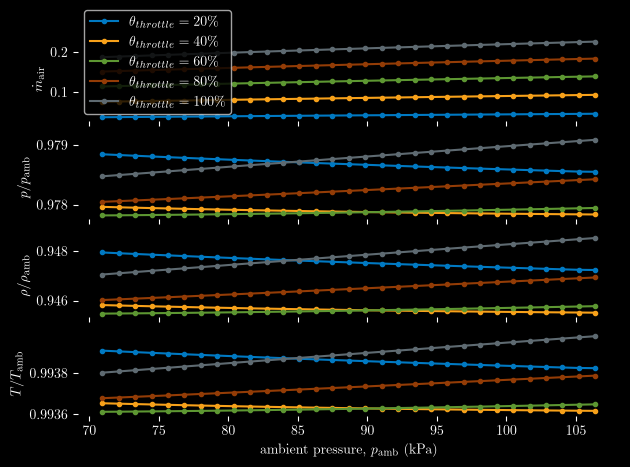

In [88]:
pressure_ambient_vec = 101325.0 * np.linspace(0.70, 1.05, 31)
area_throttle_open = 0.25 * np.pi * 0.075**2

fig, axes = plt.subplots(4, 1, sharex=True)

theta_throttle_vec = np.linspace(0.0, 1.0, 6)[1:]

for theta_throttle in theta_throttle_vec:
    res_vec = []
    for pressure_ambient in pressure_ambient_vec:
        resid = factory_residual_otto_inlet(
            pressure_ambient,
            1.225,
            area_throttle=area_throttle_open,
            theta_throttle=theta_throttle,
            # Ci=0.55,
        )
        res = minimize(
            resid,
            [-1.0, 4.0],
            # bounds=[(0.0, None), (0.0, 1.0)],
            # method="COBYLA",
        )
        res_vec.append((np.exp(res.x[0]), 1 / (1 + np.exp(-res.x[1]))))
        print(res.status, res.message)

    res_vec = np.array(res_vec)

    axes[0].plot(
        pressure_ambient_vec / 1000,
        res_vec[:, 0],
        ".-",
        label=f"$\\theta_{{throttle}}={theta_throttle * 100:.0f}\\%$",
    )
    axes[1].plot(
        pressure_ambient_vec / 1000,
        res_vec[:, 1],
        ".-",
        label=f"$\\theta_{{throttle}}={theta_throttle * 100:.0f}\\%$",
    )
    axes[2].plot(
        pressure_ambient_vec / 1000,
        density_ratio_rev_adiabatic(res_vec[:, 1]),
        ".-",
        label=f"$\\theta_{{throttle}}={theta_throttle * 100:.0f}\\%$",
    )
    axes[3].plot(
        pressure_ambient_vec / 1000,
        temperature_ratio_rev_adiabatic(res_vec[:, 1]),
        ".-",
        label=f"$\\theta_{{throttle}}={theta_throttle * 100:.0f}\\%$",
    )
axes[-1].set_xlabel("ambient pressure, $p_\\text{amb}$ (kPa)")
axes[0].set_ylabel("$\\dot{m}_\\text{air}$")
axes[1].set_ylabel("$p/p_\\text{amb}$")
axes[2].set_ylabel("$\\rho/\\rho_\\text{amb}$")
axes[3].set_ylabel("$T/T_\\text{amb}$")
axes[0].legend()
fig.tight_layout()
plt.show()